# Lab 7

Generative adversarial network
By Alex Horyshevskyi  

[Overview of GAN by IBM](https://www.ibm.com/think/topics/generative-adversarial-networks)

### Installing dependencies

In [1]:
%pip install keras numpy scikit-learn matplotlib kagglehub albumentations --quiet
%pip install --pre torch torchvision --index-url https://download.pytorch.org/whl/nightly/cu132 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### GPU check

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [3]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation will be performed on: {device}")

torch.set_float32_matmul_precision('high')

Using Keras version: 3.14.0
Using PyTorch version: 2.13.0.dev20260428+cu132
Computation will be performed on: cuda


### Import libraries

In [4]:
import os
from pathlib import Path

from keras import Model
from keras.metrics import Mean

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, utils as vutils

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np

### Define GAN model

In [5]:
class GAN(Model):
    """Base GAN. Subclasses implement train_step(); train() runs the epoch loop."""

    def __init__(self, discriminator, generator, latent_dim, device):
        super().__init__()
        self.discriminator = discriminator
        self.generator     = generator
        self.latent_dim    = latent_dim
        self.device        = device
        self.d_loss_metric = Mean(name="d_loss")
        self.g_loss_metric = Mean(name="g_loss")

    def compile(self, d_optimizer, g_optimizer, loss_fn=None):
        super().compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer
        self.loss_fn     = loss_fn

    @property
    def metrics(self):
        return [self.d_loss_metric, self.g_loss_metric]

    def train(self, loader, epochs, on_epoch_end=None):
        d_losses, g_losses = [], []
        for epoch in range(epochs):
            epoch_d, epoch_g = [], []
            for batch in loader:
                d_loss, g_loss = self.train_step(batch)
                epoch_d.append(d_loss)
                epoch_g.append(g_loss)
            d_losses.append(float(np.mean(epoch_d)))
            g_losses.append(float(np.mean(epoch_g)))
            if on_epoch_end:
                on_epoch_end(epoch, epochs, d_losses[-1], g_losses[-1])
        return d_losses, g_losses

### BCGAN model

In [6]:
class BCGAN(GAN):
    """GAN trained with BCE loss. Supports unconditional and class-conditional modes."""

    def __init__(
        self,
        discriminator,
        generator,
        latent_dim,
        device,
        n_g_steps: int = 1,
        real_label: float = 0.9,
        num_classes: int | None = None,
    ):
        super().__init__(discriminator, generator, latent_dim, device)
        self.n_g_steps = n_g_steps
        self.real_label = real_label
        self.num_classes = num_classes

    def _rand_labels(self, bs):
        return torch.randint(0, self.num_classes, (bs,), device=self.device)

    def _G(self, z, labels=None):
        return self.generator(z, labels) if labels is not None else self.generator(z)

    def _D(self, x, labels=None):
        return (
            self.discriminator(x, labels)
            if labels is not None
            else self.discriminator(x)
        )

    def train_step(self, batch):
        real_imgs = batch[0] if isinstance(batch, (list, tuple)) else batch
        real_labels = (
            batch[1].to(self.device, non_blocking=True)
            if self.num_classes and isinstance(batch, (list, tuple))
            else None
        )
        bs = real_imgs.size(0)
        real_imgs = real_imgs.to(self.device, non_blocking=True)

        # Discriminator — fp32: bfloat16 kills log-gradients in BCEWithLogitsLoss
        self.discriminator.zero_grad(set_to_none=True)
        d_real = self.loss_fn(
            self._D(real_imgs, real_labels),
            torch.full((bs, 1), self.real_label, device=self.device),
        )
        z = torch.randn(bs, self.latent_dim, device=self.device)
        flbls = self._rand_labels(bs) if self.num_classes else None
        d_fake = self.loss_fn(
            self._D(self._G(z, flbls).detach(), flbls),
            torch.zeros(bs, 1, device=self.device),
        )
        d_loss = d_real + d_fake
        d_loss.backward()
        self.d_optimizer.step()

        # Generator (n_g_steps per discriminator step)
        for _ in range(self.n_g_steps):
            self.generator.zero_grad(set_to_none=True)
            z = torch.randn(bs, self.latent_dim, device=self.device)
            glbls = self._rand_labels(bs) if self.num_classes else None
            g_loss = self.loss_fn(
                self._D(self._G(z, glbls), glbls),
                torch.ones(bs, 1, device=self.device),
            )
            g_loss.backward()
            self.g_optimizer.step()

        return d_loss.item(), g_loss.item()

#### Labelled sample grids helper

In [7]:
def show_conditional_samples(G, title, n_per_class=5):
    G.eval()

    imgs = []

    for _ in range(n_per_class):
        noise  = torch.randn(NUM_CLASSES, LATENT_DIM, device=device)
        labels = torch.arange(NUM_CLASSES, device=device)
        with torch.no_grad():
            img = G(noise, labels).cpu().numpy().transpose(0, 2, 3, 1)
            img = np.clip((img + 1) / 2, 0, 1)
            imgs.append(img)
        
    fig, axes = plt.subplots(n_per_class, NUM_CLASSES, figsize=(14, 2*n_per_class))
    for i in range(n_per_class):
        for ax, img, cls in zip(axes if n_per_class == 1 else axes[i], imgs[i], CIFAR10_CLASSES):
            ax.imshow(img)
            ax.set_title(cls, fontsize=8)
            ax.axis("off")
    plt.suptitle(title, y=1.05)
    plt.tight_layout()
    plt.show()

## Use Case 1: Simple GAN on MNIST (MLP)

A Multilayer Perceptron GAN trained on MNIST. The Generator maps a 100-dimensional latent vector to a 28×28 grayscale image, the Discriminator classifies Real vs. Fake using flattened pixel vectors.

**What to observe:** Generator and Discriminator losses *oscillate* rather than converge to zero - that oscillation is the adversarial tug-of-war working correctly.

Loading pre-trained GAN weights...


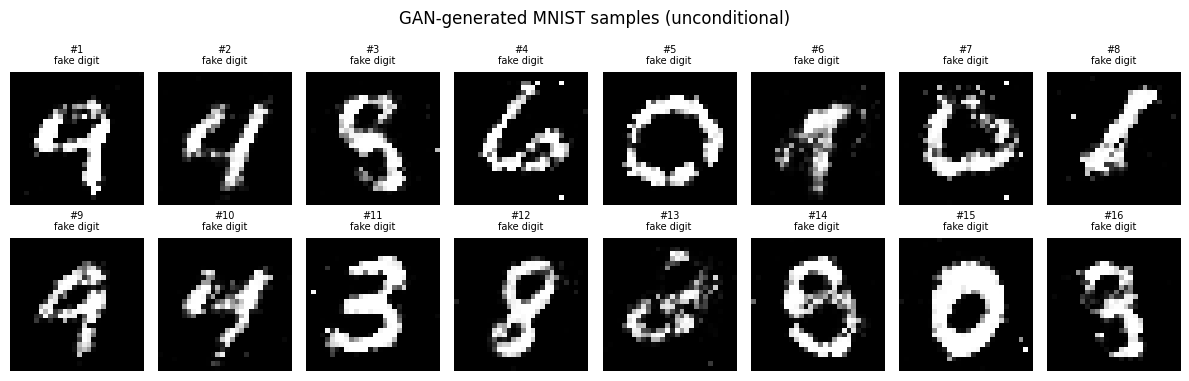

In [23]:
torch.backends.cudnn.benchmark = True

LATENT_DIM = 100
IMAGE_DIM = 28 * 28
BATCH_SIZE = 256
NUM_EPOCHS = 50
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5]),
    ]
)
mnist_train = datasets.MNIST(
    root="data/mnist", train=True, download=True, transform=transform
)
loader = DataLoader(
    mnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)


class MLPGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT_DIM, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, IMAGE_DIM),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class MLPDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(IMAGE_DIM, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)


G = torch.compile(MLPGenerator().to(device))
D = torch.compile(MLPDiscriminator().to(device))

gan = BCGAN(
    discriminator=D,
    generator=G,
    latent_dim=LATENT_DIM,
    device=device,
    n_g_steps=2,
    real_label=1.0,  # no smoothing needed — MNIST D doesn't overpower G
    num_classes=None,  # unconditional
)

fixed_noise = torch.randn(16, LATENT_DIM, device=device)

if Path("saved_models/gan_mnist.pth").exists():
    print("Loading pre-trained GAN weights...")
    state = torch.load("saved_models/gan_mnist.pth", map_location=device)
    G.load_state_dict(state["G"])
    D.load_state_dict(state["D"])
else:
    gan.compile(
        d_optimizer=Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.999)),
        g_optimizer=Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999)),
        loss_fn=nn.BCEWithLogitsLoss(),
    )

    def on_epoch_end(epoch, total, d_loss, g_loss):
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"Epoch [{epoch+1:>3}/{total}]  D-loss: {d_loss:.4f}  G-loss: {g_loss:.4f}"
            )


    d_losses, g_losses = gan.train(loader, NUM_EPOCHS, on_epoch_end=on_epoch_end)
    print("Training complete.")

    # Loss curves
    plt.figure(figsize=(9, 4))
    plt.plot(d_losses, label="Discriminator loss")
    plt.plot(g_losses, label="Generator loss")
    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title("MNIST MLP-GAN - Training Losses")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Generated samples
G.eval()
with torch.no_grad():
    fake = G(fixed_noise).cpu().numpy()

fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i, (ax, img) in enumerate(zip(axes.flat, fake)):
    ax.imshow(img.squeeze(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"#{i+1}\nfake digit", fontsize=7)
    ax.axis("off")
plt.suptitle("GAN-generated MNIST samples (unconditional)")
plt.tight_layout()
plt.show()

In [9]:
os.makedirs("saved_models", exist_ok=True)

print("Saving model weights...")
Path("saved_models/gan_mnist.pth").unlink(missing_ok=True)  # remove old file if it exists

torch.save({"G": G.state_dict(), "D": D.state_dict()}, "saved_models/gan_mnist.pth")
print("Model weights saved to 'saved_models/gan_mnist.pth'.")

Saving model weights...
Model weights saved to 'saved_models/gan_mnist.pth'.


## Use Case 2: Deep Convolutional GAN (DCGAN) on CIFAR-10

A **Deep Convolutional GAN** trained on CIFAR-10 (32×32 RGB).  
The Generator uses `ConvTranspose2d` to upsample from a 4×4 spatial seed to a full-color image, the Discriminator uses `Conv2d` to downsample and classify.

**Architectural Improvement:** A second variant replaces BCE loss with **Wasserstein Loss** (WGAN-GP) to counter mode collapse and improve training stability.

In [10]:
LATENT_DIM = 128
NUM_CLASSES = 10
CHANNELS = 3
IMAGE_SIZE = 32
NGF = 128
NDF = 128
BATCH_SIZE = 256
NUM_EPOCHS = 50
LAMBDA_GP = 10
N_CRITIC = 3
N_G_STEPS = 2
OUTPUT_DIR = "output/uc2_images"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CIFAR10_CLASSES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

transform = transforms.Compose(
    [
        transforms.Resize(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ]
)

aug_transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
    ]
)


class AugmentedDataset(Dataset):
    def __init__(self, dataset, aug):
        self.dataset = dataset
        self.aug = aug

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        img_np = img.permute(1, 2, 0).numpy()
        augmented = self.aug(image=img_np)
        img = torch.from_numpy(augmented["image"]).permute(2, 0, 1)
        return img, label

    def __len__(self):
        return len(self.dataset)


cifar_train = AugmentedDataset(
    datasets.CIFAR10(
        root="data/cifar10", train=True, download=True, transform=transform
    ),
    aug=aug_transform,
)
loader = DataLoader(
    cifar_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)


def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, (nn.BatchNorm2d, nn.InstanceNorm2d)):
        if m.weight is not None:
            nn.init.normal_(m.weight, 1.0, 0.02)
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)


class SelfAttention(nn.Module):
    """Scaled dot-product self-attention at a given spatial resolution (SA-GAN)."""

    def __init__(self, channels):
        super().__init__()
        self.query = nn.Conv2d(channels, channels // 8, 1)
        self.key = nn.Conv2d(channels, channels // 8, 1)
        self.value = nn.Conv2d(channels, channels, 1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        q = self.query(x).view(B, -1, H * W).permute(0, 2, 1)
        k = self.key(x).view(B, -1, H * W)
        attn = torch.softmax(q @ k / (C**0.5), dim=-1)
        v = self.value(x).view(B, -1, H * W)
        out = (v @ attn.permute(0, 2, 1)).view(B, C, H, W)
        return self.gamma * out + x


class CDCGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_emb = nn.Embedding(NUM_CLASSES, LATENT_DIM)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(LATENT_DIM * 2, NGF * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(NGF * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(NGF * 8, NGF * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(NGF * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(NGF * 4, NGF * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(NGF * 2),
            nn.ReLU(True),
            SelfAttention(NGF * 2),
            nn.ConvTranspose2d(NGF * 2, CHANNELS, 4, 2, 1, bias=False),
            nn.Tanh(),
        )
        self.apply(weights_init)

    def forward(self, z, labels):
        emb = self.label_emb(labels)
        return self.net(torch.cat([z, emb], dim=1).view(-1, LATENT_DIM * 2, 1, 1))


class CDCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_emb = nn.Embedding(NUM_CLASSES, IMAGE_SIZE * IMAGE_SIZE)
        self.net = nn.Sequential(
            nn.Conv2d(CHANNELS + 1, NDF, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            SelfAttention(NDF),
            nn.Conv2d(NDF, NDF * 2, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(NDF * 2, affine=True),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(NDF * 2, NDF * 4, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(NDF * 4, affine=True),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(NDF * 4, 1, 4, 1, 0, bias=False),
        )
        self.apply(weights_init)

    def forward(self, x, labels):
        emb = self.label_emb(labels).view(-1, 1, IMAGE_SIZE, IMAGE_SIZE)
        return self.net(torch.cat([x, emb], dim=1)).view(-1, 1)


def save_grid(G, noise, labels, epoch, tag="cdcgan"):
    G.eval()
    with torch.no_grad():
        imgs = G(noise, labels).cpu()
    vutils.save_image(
        imgs,
        os.path.join(OUTPUT_DIR, f"{tag}_epoch{epoch:03d}.png"),

        normalize=True,
        nrow=NUM_CLASSES,
    )
    G.train()


fixed_noise = torch.randn(NUM_CLASSES * 2, LATENT_DIM, device=device)
fixed_labels = torch.tensor(list(range(NUM_CLASSES)) * 2, device=device)

### Variant A: Conditional DCGAN - BCE + label smoothing

In [11]:
G_bce = torch.compile(CDCGenerator().to(device))
D_bce = torch.compile(CDCDiscriminator().to(device))

gan_bce = BCGAN(
    discriminator=D_bce,
    generator=G_bce,
    latent_dim=LATENT_DIM,
    device=device,
    n_g_steps=N_G_STEPS,
    real_label=0.85,
    num_classes=NUM_CLASSES,
)

if os.path.exists("saved_models/generator_bce.pth") and os.path.exists("saved_models/discriminator_bce.pth"):
    G_bce.load_state_dict(torch.load("saved_models/generator_bce.pth"))
    D_bce.load_state_dict(torch.load("saved_models/discriminator_bce.pth"))
    print("Loaded pre-trained models.")
else:
    print("No pre-trained models found. Starting training from scratch.")
    gan_bce.compile(
        d_optimizer=Adam(D_bce.parameters(), lr=1e-4, betas=(0.5, 0.999)),
        g_optimizer=Adam(G_bce.parameters(), lr=2e-4, betas=(0.5, 0.999)),
        loss_fn=nn.BCEWithLogitsLoss(),
    )


    def on_epoch_end_bce(epoch, total, d_loss, g_loss):
        if (epoch + 1) % 5 == 0 or epoch == 0:
            save_grid(G_bce, fixed_noise, fixed_labels, epoch + 1, tag="bce")
            print(f"  Epoch [{epoch+1:>3}/{total}]  D: {d_loss:.4f}  G: {g_loss:.4f}")


    d_losses_bce, g_losses_bce = gan_bce.train(
        loader, NUM_EPOCHS, on_epoch_end=on_epoch_end_bce
    )

Loaded pre-trained models.


In [12]:
Path("saved_models").mkdir(exist_ok=True)
Path("saved_models/generator_bce.pth").unlink(missing_ok=True)
Path("saved_models/discriminator_bce.pth").unlink(missing_ok=True)
torch.save(G_bce.state_dict(), "saved_models/generator_bce.pth")
torch.save(D_bce.state_dict(), "saved_models/discriminator_bce.pth")

### Variant B: Conditional WGAN-GP

In [13]:
class WGANGP(GAN):
    """Wasserstein GAN with gradient penalty. Supports unconditional and class-conditional modes.

    The critic runs n_critic steps per generator step on independent batches drawn
    from the same loader iteration, matching the original WGAN-GP paper protocol.
    """

    def __init__(
        self,
        discriminator,
        generator,
        latent_dim,
        device,
        n_critic: int = 5,
        gp_weight: float = 10.0,
        num_classes: int | None = None,
    ):
        super().__init__(discriminator, generator, latent_dim, device)
        self.n_critic = n_critic
        self.gp_weight = gp_weight
        self.num_classes = num_classes

    def _rand_labels(self, bs):
        return torch.randint(0, self.num_classes, (bs,), device=self.device)

    def _G(self, z, labels=None):
        return self.generator(z, labels) if labels is not None else self.generator(z)

    def _D(self, x, labels=None):
        return (
            self.discriminator(x, labels)
            if labels is not None
            else self.discriminator(x)
        )

    @torch.compiler.disable  # create_graph=True (double backward) is incompatible with torch.compile
    def gradient_penalty(self, real, fake, labels=None):
        bs = real.size(0)
        alpha = torch.rand(bs, 1, 1, 1, device=self.device)
        interp = (alpha * real + (1 - alpha) * fake).requires_grad_(True)
        grads = torch.autograd.grad(
            outputs=self._D(interp, labels),
            inputs=interp,
            grad_outputs=torch.ones(bs, 1, device=self.device),
            create_graph=True,
            retain_graph=True,
        )[0].view(bs, -1)
        return ((grads.norm(2, dim=1) - 1) ** 2).mean()

    def train_step(self, batch):
        real_imgs = batch[0] if isinstance(batch, (list, tuple)) else batch
        real_labels = (
            batch[1].to(self.device, non_blocking=True)
            if self.num_classes and isinstance(batch, (list, tuple))
            else None
        )
        bs = real_imgs.size(0)
        real_imgs = real_imgs.to(self.device, non_blocking=True).float()

        # Critic (n_critic steps on the same batch — valid per WGAN-GP theory)
        for _ in range(self.n_critic):
            self.discriminator.zero_grad(set_to_none=True)
            z = torch.randn(bs, self.latent_dim, device=self.device)
            flbls = self._rand_labels(bs) if self.num_classes else None
            fake = self._G(z, flbls).detach().float()
            gp = self.gradient_penalty(real_imgs, fake, real_labels)
            d_loss = (
                self._D(fake, flbls).mean()
                - self._D(real_imgs, real_labels).mean()
                + self.gp_weight * gp
            )
            d_loss.backward()
            self.d_optimizer.step()

        # Generator
        self.generator.zero_grad(set_to_none=True)
        z = torch.randn(bs, self.latent_dim, device=self.device)
        glbls = self._rand_labels(bs) if self.num_classes else None
        g_loss = -self._D(self._G(z, glbls), glbls).mean()
        g_loss.backward()
        self.g_optimizer.step()

        return d_loss.item(), g_loss.item()

In [14]:
G_wgan = torch.compile(CDCGenerator().to(device))
D_wgan = CDCDiscriminator().to(device)

gan_wgan = WGANGP(
    discriminator=D_wgan,
    generator=G_wgan,
    latent_dim=LATENT_DIM,
    device=device,
    n_critic=N_CRITIC,
    gp_weight=LAMBDA_GP,
    num_classes=NUM_CLASSES,
)

if os.path.exists("saved_models/generator_wgan.pth") and os.path.exists("saved_models/discriminator_wgan.pth"):
    G_wgan.load_state_dict(torch.load("saved_models/generator_wgan.pth"))
    D_wgan.load_state_dict(torch.load("saved_models/discriminator_wgan.pth"))
    print("Loaded pre-trained WGAN-GP models.")
else:
    print("No pre-trained WGAN-GP models found. Starting training from scratch.")
    gan_wgan.compile(
        d_optimizer=Adam(D_wgan.parameters(), lr=1e-4, betas=(0.0, 0.9)),
        g_optimizer=Adam(G_wgan.parameters(), lr=2e-4, betas=(0.0, 0.9)),
    )


    def on_epoch_end_wgan(epoch, total, d_loss, g_loss):
        if (epoch + 1) % 5 == 0 or epoch == 0:
            save_grid(G_wgan, fixed_noise, fixed_labels, epoch + 1, tag="wgan")
            print(f"  Epoch [{epoch+1:>3}/{total}]  Critic: {d_loss:.4f}  G: {g_loss:.4f}")


    d_losses_wgan, g_losses_wgan = gan_wgan.train(
        loader, NUM_EPOCHS, on_epoch_end=on_epoch_end_wgan
    )

Loaded pre-trained WGAN-GP models.


In [15]:
Path("saved_models").mkdir(exist_ok=True)
Path("saved_models/generator_wgan.pth").unlink(missing_ok=True)
Path("saved_models/discriminator_wgan.pth").unlink(missing_ok=True)
torch.save(G_wgan.state_dict(), "saved_models/generator_wgan.pth")
torch.save(D_wgan.state_dict(), "saved_models/discriminator_wgan.pth")

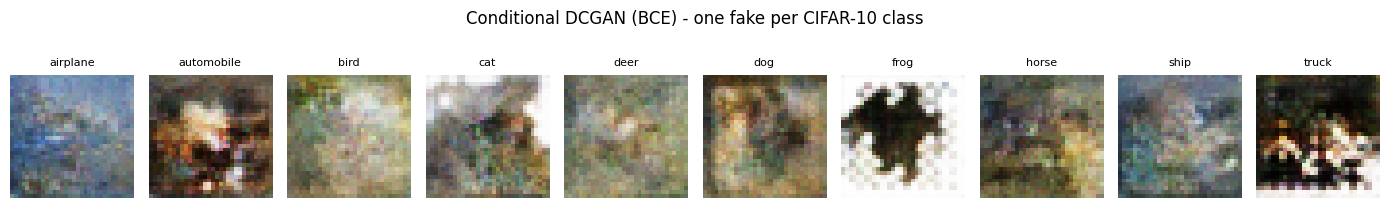

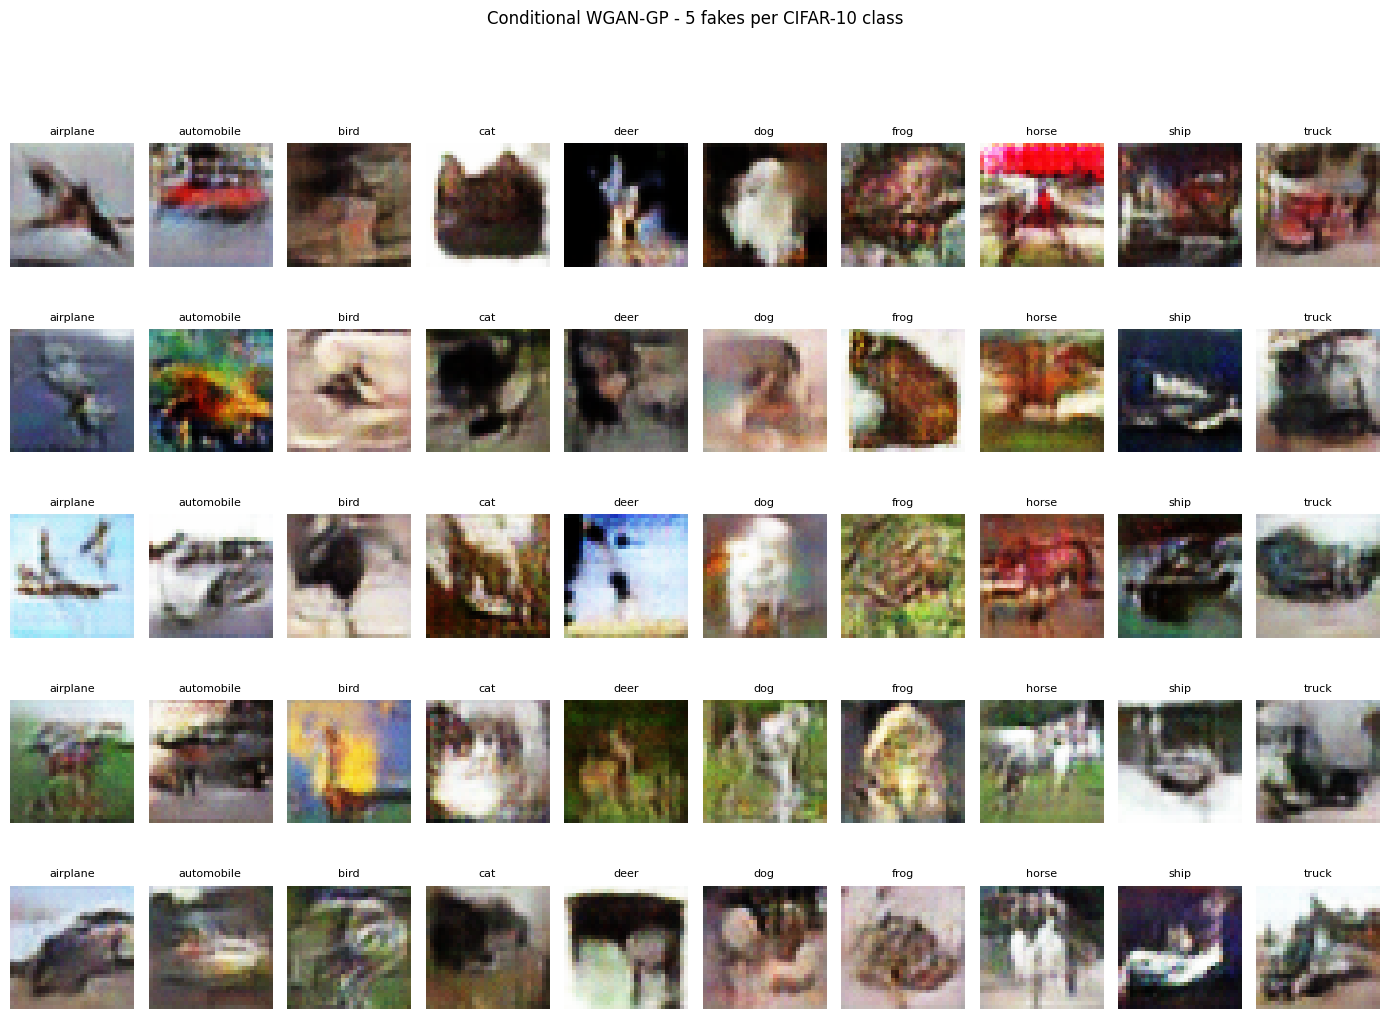

In [18]:
# Loss comparison
# fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# axes[0].plot(d_losses_bce, label="D loss")
# axes[0].plot(g_losses_bce, label="G loss")
# axes[0].set_title("Conditional DCGAN - BCE")
# axes[0].set_xlabel("Epoch")
# axes[0].legend()

# axes[1].plot(d_losses_wgan, label="Critic")
# axes[1].plot(g_losses_wgan, label="G loss")
# axes[1].set_title("Conditional WGAN-GP")
# axes[1].set_xlabel("Epoch")
# axes[1].legend()

# plt.tight_layout()
# plt.show()

show_conditional_samples(G_bce, f"Conditional DCGAN (BCE) - one fake per CIFAR-10 class", n_per_class=1)

n_per_class = 5
title = "one fake" if n_per_class == 1 else f"{n_per_class} fakes"
show_conditional_samples(G_wgan, f"Conditional WGAN-GP - {title} per CIFAR-10 class")